# Diffusion Models from Scratch: DiT, DDPM, DDIM, Flow Matching & Latent Diffusion

*Created by Jay Mahajan & Ozgur Kara (Spring 2026 CS 444 TAs)*

You will be implementing a custom Diffusion Transformer. Your goal is to implement a transformer (Part A) and then use it to generate handwritten digits (Part B).

Files that need to be edited: ```DiT.py```

In [1]:
!pip install torch torchvision matplotlib tqdm einops torchmetrics[image] torch-fidelity diffusers


In [2]:
# Make the repository root the working directory so `src/`, `data/` and `checkpoints/` resolve
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
os.makedirs("checkpoints", exist_ok=True)

## Part A: Implementing the transformer

You need to implement the transformer in ```DiT.py```. You will need to follow the instructions in the website.

For each sub part, you can test if it works by running ```python tests.py```. **You must pass all tests in order to get full credit!**

In [3]:
!PYTHONPATH=src python tests/test_dit.py

..........
----------------------------------------------------------------------
Ran 10 tests in 1.261s

OK


## Part B: Training with DDPM

Once you have the transformer built, you will train it with DDPM.

In [4]:
import torch
from DiT import DiT
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from torchvision.utils import make_grid
from torchvision.transforms import functional as F
import matplotlib.pyplot as plt
from torchmetrics.image.fid import FrechetInceptionDistance
%matplotlib inline

In [5]:
### Set Hyperparameters, do not change these, unless you are doing extra credit
res = 28
patch_size = 4
channels = 1
heads = 8
hidden_dim = 256
num_patch = (res // patch_size) ** 2
ff_dim = 1024
time_emb_dim = 256
num_blocks = 5
num_timesteps = 300

beta_0 = 0.0001
beta_t = 0.02

batch_size = 64
num_epoch = 100
lr=4e-4

In [6]:
### Helper function to show images
def show_images(imgs):
    batch_min = imgs.view(imgs.size(0), -1).min(dim=1, keepdim=True)[0].view(-1, 1, 1, 1)
    batch_max = imgs.view(imgs.size(0), -1).max(dim=1, keepdim=True)[0].view(-1, 1, 1, 1)
    imgs = (imgs - batch_min) / (batch_max - batch_min + 1e-6)
    imgs = imgs.detach().cpu()
    grid = make_grid(imgs, nrow=5)
    plt.axis('off')
    plt.imshow(grid.permute(1, 2, 0))
    plt.show()

In [28]:
class Diffusion:

    def __init__(self):
        trans = transforms.Compose([
            transforms.Resize(res),
            transforms.ToTensor(),
            transforms.Normalize((0.5), (0.5)),
        ])
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.fid = FrechetInceptionDistance(feature=2048, normalize=True).to(self.device)
        self.num_fid_samples = 1000

        self.dataset = datasets.MNIST(root='./data', train=True, download=True, transform=trans)
        self.training_dataloader = DataLoader(self.dataset, batch_size=batch_size, shuffle=True)

        self.betas      = torch.linspace(beta_0, beta_t, num_timesteps).to(self.device)
        self.alphas     = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

        self.model = DiT(
            patch_size=patch_size,
            num_blocks=num_blocks,
            num_heads=heads,
            ff_dim=ff_dim,
            time_emb_dim=time_emb_dim,
            num_timesteps=num_timesteps,
            hidden_dim=hidden_dim,
            num_patches=num_patch,
            num_channels=channels,
        ).to(self.device)

        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        self.loss_fn   = torch.nn.MSELoss()

        self._precompute_fid_real()

    def train(self):
        total_losses = []
        all_fids     = []
        fid_epochs   = []

        for e in range(num_epoch):
            self.model.train()
            all_losses = []

            for imgs, _ in tqdm(self.training_dataloader):
                imgs  = imgs.to(self.device)
                t     = torch.randint(0, num_timesteps, (imgs.shape[0],), device=self.device)
                noise = torch.randn_like(imgs)
                ab    = self.alphas_bar[t].view(-1, 1, 1, 1)
                x_t   = torch.sqrt(ab) * imgs + torch.sqrt(1.0 - ab) * noise

                noise_pred = self.model(x_t, t)
                loss = self.loss_fn(noise_pred, noise)

                self.optimizer.zero_grad()
                loss.backward()
                self.optimizer.step()
                all_losses.append(loss.item())

            print("Avg Loss:", sum(all_losses) / len(all_losses))
            total_losses += all_losses
            all_losses = []

            if e % 10 == 0:
                print("Epoch:", e + 1)
                torch.save(self.model.state_dict(), f'checkpoints/ddpm_epoch_{e}.pt')
                imgs    = self.run_inference()
                fid_val = self.compute_fid()
                print("FID:", fid_val)
                all_fids.append(fid_val)
                fid_epochs.append(e + 1)
                show_images(imgs)

        torch.save(self.model.state_dict(), 'checkpoints/ddpm_final.pt')
        print('Model saved in Drive.')

        print("Final Epoch:")
        final_imags = self.run_inference()
        show_images(final_imags)

        plt.plot(total_losses)
        plt.title("Loss")
        plt.xlabel("Steps")
        plt.show()

        plt.plot(fid_epochs, all_fids)
        plt.title("FID")
        plt.xlabel("Epochs")
        plt.show()

    def run_inference(self, num_samples=20):
        self.model.eval()
        with torch.no_grad():
            x = torch.randn(num_samples, channels, res, res, device=self.device)
            for t in reversed(range(num_timesteps)):
                t_tensor    = torch.full((num_samples,), t, device=self.device, dtype=torch.long)
                beta_t      = self.betas[t]
                alpha_t     = self.alphas[t]
                alpha_bar_t = self.alphas_bar[t]
                eps_pred    = self.model(x, t_tensor)
                coeff       = beta_t / torch.sqrt(1.0 - alpha_bar_t)
                mean        = (1.0 / torch.sqrt(alpha_t)) * (x - coeff * eps_pred)
                if t > 0:
                    x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
                else:
                    x = mean
            return x

    def _prepare_for_fid(self, imgs_m1_1):
        imgs = (imgs_m1_1 / 2 + 0.5).clamp(0, 1)
        imgs = imgs.repeat(1, 3, 1, 1)
        imgs = F.resize(imgs, [75, 75], antialias=True)
        return imgs

    def _precompute_fid_real(self):
        print(f"[FID] Pre-computing real features on up to {self.num_fid_samples} samples...")
        total = 0
        for imgs, _ in self.dataset:
            imgs = imgs.to(self.device)
            imgs = self._prepare_for_fid(imgs)
            self.fid.update(imgs, real=True)
            total += imgs.size(0)
            if total >= self.num_fid_samples:
                break
        print(f"[FID] Real features ready ({total} samples).")

    @torch.no_grad()
    def compute_fid(self):
        if self.fid is None:
            return None
        self.model.eval()
        batch  = 200
        needed = self.num_fid_samples
        done   = 0
        while done < needed:
            n    = min(batch, needed - done)
            fake = self.run_inference(num_samples=n)
            fake = self._prepare_for_fid(fake.to(self.device))
            self.fid.update(fake, real=False)
            done += n
        val = float(self.fid.compute().item())
        self.fid.reset()
        self._precompute_fid_real()
        self.model.train()
        return val

[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).


Avg Loss: 0.1588750055222623
Epoch: 1
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 290.96197509765625


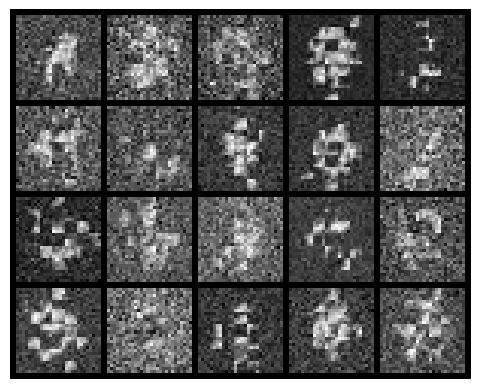

Avg Loss: 0.0953559279680125


Avg Loss: 0.08334155245694017


Avg Loss: 0.0791221557776811


Avg Loss: 0.07652467773603733


Avg Loss: 0.07406878358583206


Avg Loss: 0.0717304949559319


Avg Loss: 0.06888389005573956


Avg Loss: 0.06413779312423043


Avg Loss: 0.060272670857338256


Avg Loss: 0.05816704445063814
Epoch: 11
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 206.07937622070312


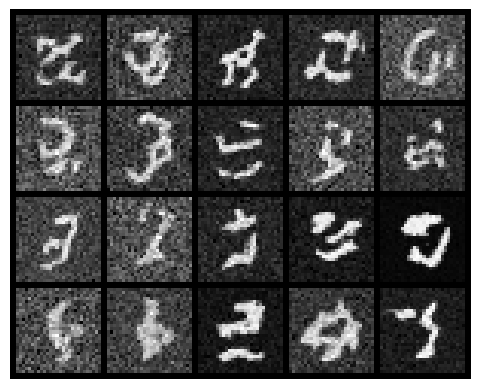

Avg Loss: 0.05645443885517654


Avg Loss: 0.055452716431574525


Avg Loss: 0.054462491147426656


Avg Loss: 0.053710385140325466


Avg Loss: 0.052634255686548476


Avg Loss: 0.052031914471213754


Avg Loss: 0.05118769953357004


Avg Loss: 0.051093334026301084


Avg Loss: 0.05026211398941621


Avg Loss: 0.0497189579702326
Epoch: 21
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 142.2035675048828


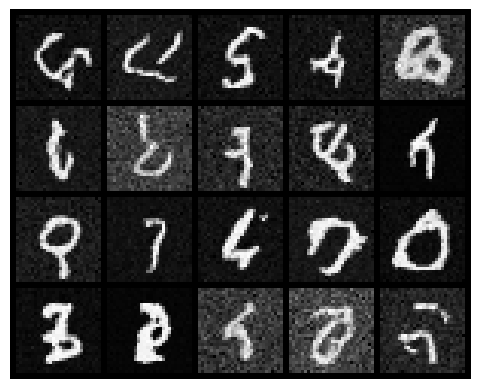

Avg Loss: 0.049549518244416474


Avg Loss: 0.04892854159400026


Avg Loss: 0.048845035605815684


Avg Loss: 0.04790471335734004


Avg Loss: 0.04824864983892263


Avg Loss: 0.04769536756725708


Avg Loss: 0.04752861531272626


Avg Loss: 0.047284661265991644


Avg Loss: 0.04700832830261447


Avg Loss: 0.046856973213014574
Epoch: 31
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 130.32827758789062


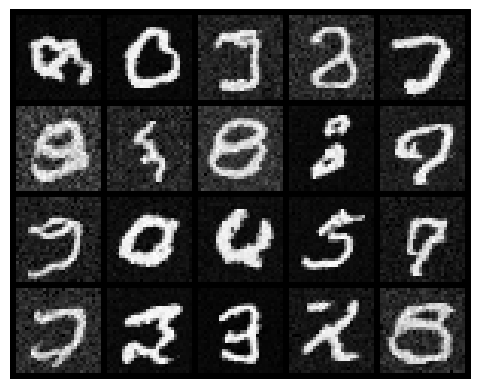

Avg Loss: 0.04712523375032172


Avg Loss: 0.046271918905473976


Avg Loss: 0.04631954426370831


Avg Loss: 0.046318660095048106


Avg Loss: 0.04633884366228382


Avg Loss: 0.04558084365020174


Avg Loss: 0.04566140024900945


Avg Loss: 0.04581240567364799


Avg Loss: 0.04536806191526242


Avg Loss: 0.04543249727661676
Epoch: 41
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 115.39879608154297


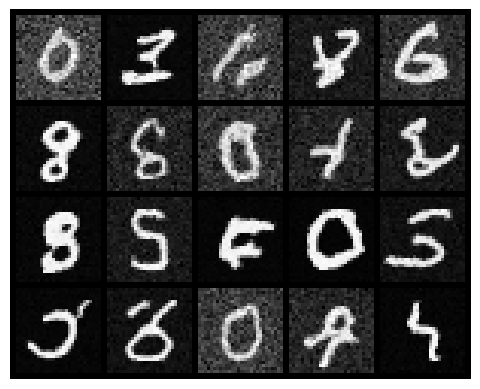

Avg Loss: 0.04549398627291038


Avg Loss: 0.04525469893069346


Avg Loss: 0.04470312052857139


Avg Loss: 0.044777566972158865


Avg Loss: 0.04499069365587379


Avg Loss: 0.04459589978914334


Avg Loss: 0.04460845261947242


Avg Loss: 0.04477866083335902


Avg Loss: 0.04415514639048561


Avg Loss: 0.04461108969806481
Epoch: 51
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 130.82369995117188


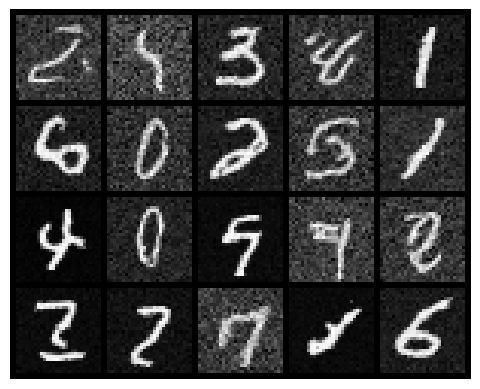

Avg Loss: 0.04370311584307759


Avg Loss: 0.04413929451376136


Avg Loss: 0.044174900071929764


Avg Loss: 0.0439378679263344


Avg Loss: 0.04426344612966786


Avg Loss: 0.04396031402162651


Avg Loss: 0.043689964424524864


Avg Loss: 0.043777963448403234


Avg Loss: 0.04371997342705091


Avg Loss: 0.04378519528336934
Epoch: 61
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 98.35700225830078


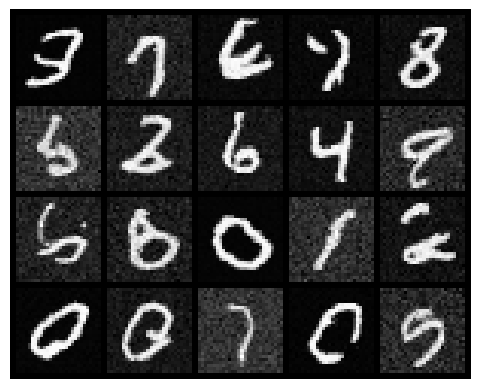

Avg Loss: 0.04334382056943707


Avg Loss: 0.043347841085020156


Avg Loss: 0.04340394627032822


Avg Loss: 0.04331625893370493


Avg Loss: 0.04341828903115825


Avg Loss: 0.04322407864876139


Avg Loss: 0.04318676946728405


Avg Loss: 0.043258806380794754


Avg Loss: 0.04289781516874586


Avg Loss: 0.04304952726665654
Epoch: 71
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 140.1199493408203


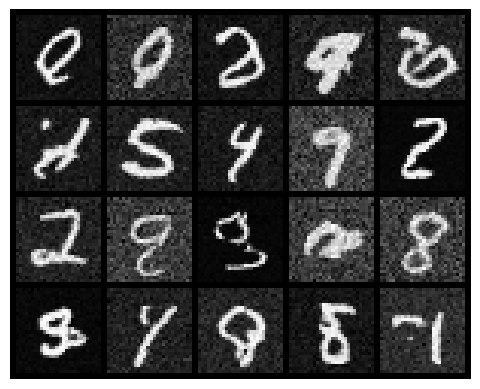

Avg Loss: 0.04312221451537378


Avg Loss: 0.04300212132722648


Avg Loss: 0.0432145545727758


Avg Loss: 0.04267473542876144


Avg Loss: 0.04260674434731891


Avg Loss: 0.04281808384485654


Avg Loss: 0.04274407420744265


Avg Loss: 0.04286615121990506


Avg Loss: 0.04274220558912007


Avg Loss: 0.042735267243882234
Epoch: 81
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 101.2421646118164


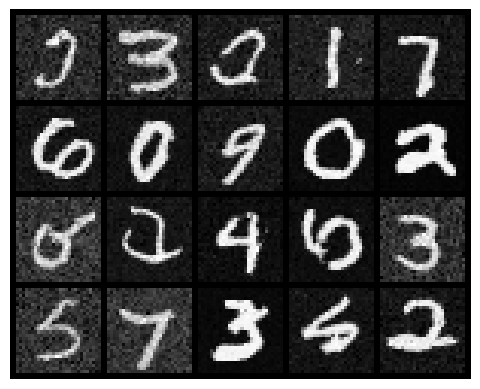

Avg Loss: 0.04260766392013729


Avg Loss: 0.042561309817217306


Avg Loss: 0.04244262815268436


Avg Loss: 0.04244832494961364


Avg Loss: 0.04211948132678581


Avg Loss: 0.04263711428003652


Avg Loss: 0.04252069682748651


Avg Loss: 0.04232380924615334


Avg Loss: 0.0422944730636217


Avg Loss: 0.04226804482561947
Epoch: 91
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 95.68953704833984


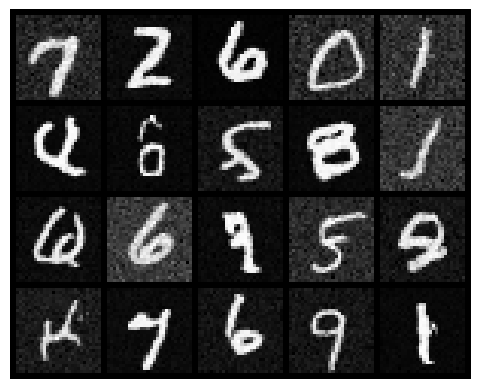

Avg Loss: 0.0425965514308068


Avg Loss: 0.042125339671445175


Avg Loss: 0.04214218325579344


Avg Loss: 0.04228123679542656


Avg Loss: 0.04214569195104179


Avg Loss: 0.0420365487314713


Avg Loss: 0.04183746960514517


Avg Loss: 0.04188644886016846


Avg Loss: 0.04182405876857576
Modelo guardado en Drive.
Final Epoch:


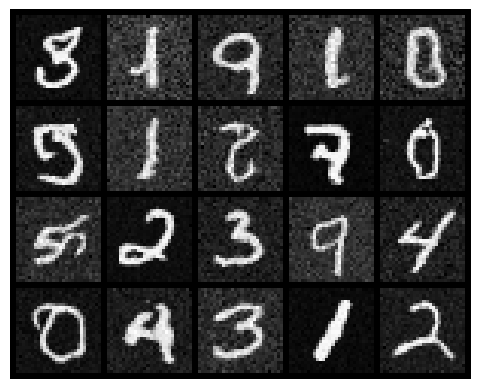

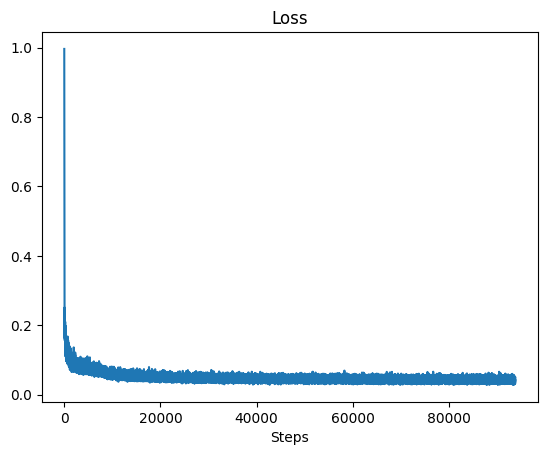

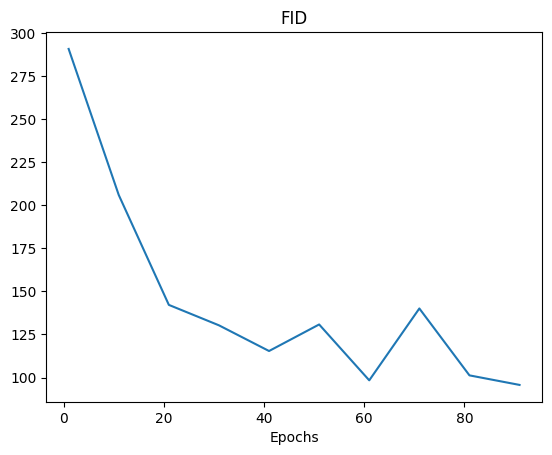

In [10]:
d = Diffusion()
d.train()

## Extensions beyond the base DDPM

DDPM model loaded from checkpoints/ddpm_final.pt
DDIM sampling done with 50 steps (vs 300 for DDPM)


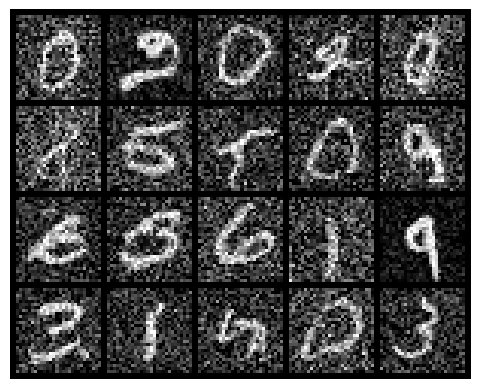

In [27]:
## DDIM
## DDIM speeds up inference by using a deterministic sampling process
## instead of the stochastic DDPM process, reducing steps from 300 to 50.

class DDIM:
    def __init__(self, ddpm_checkpoint_path, num_inference_steps=50):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.num_inference_steps = num_inference_steps

        # Same noise schedule as DDPM
        self.betas      = torch.linspace(beta_0, beta_t, num_timesteps).to(self.device)
        self.alphas     = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

        # Load the pretrained DDPM model
        self.model = DiT(
            patch_size=patch_size,
            num_blocks=num_blocks,
            num_heads=heads,
            ff_dim=ff_dim,
            time_emb_dim=time_emb_dim,
            num_timesteps=num_timesteps,
            hidden_dim=hidden_dim,
            num_patches=num_patch,
            num_channels=channels,
        ).to(self.device)
        self.model.load_state_dict(torch.load(ddpm_checkpoint_path, map_location=self.device))
        self.model.eval()
        print(f'DDPM model loaded from {ddpm_checkpoint_path}')

        # Select num_inference_steps timesteps uniformly spaced from T-1 to 0
        self.timesteps = torch.linspace(num_timesteps - 1, 0, num_inference_steps).long()

    def run_inference(self, num_samples=20):
        '''
        DDIM Sampling: deterministic, no stochastic noise.
        At each step, predict x0 from x_t and eps_pred,
        then compute x_{t-1} directly without adding noise.
        '''
        with torch.no_grad():
            x = torch.randn(num_samples, channels, res, res, device=self.device)

            for i, t in enumerate(self.timesteps):
                t_tensor = torch.full((num_samples,), t.item(), device=self.device, dtype=torch.long)
                ab_t     = self.alphas_bar[t]

                # Predict noise
                eps_pred = self.model(x, t_tensor)

                # Estimate x0 from x_t and eps_pred
                x0_pred = (x - torch.sqrt(1 - ab_t) * eps_pred) / torch.sqrt(ab_t)
                x0_pred = x0_pred.clamp(-1, 1)

                if i < len(self.timesteps) - 1:
                    t_next  = self.timesteps[i + 1]
                    ab_next = self.alphas_bar[t_next]
                    # DDIM deterministic update step, no noise added
                    x = torch.sqrt(ab_next) * x0_pred + torch.sqrt(1 - ab_next) * eps_pred
                else:
                    x = x0_pred

            return x


# Instantiate DDIM with the saved DDPM model and generate images
ddim = DDIM(ddpm_checkpoint_path='checkpoints/ddpm_final.pt', num_inference_steps=50)
imgs_ddim = ddim.run_inference(num_samples=20)
print('DDIM sampling done with 50 steps (vs 300 for DDPM)')
show_images(imgs_ddim)

## Flow Matching


In [8]:
from DiT import DiT, ContinuousTimestepEmbedder

fm_num_inference_steps = 100

class FlowMatching:

    def __init__(self):
        trans = transforms.Compose([
            transforms.Resize(res),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,)),
        ])
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.fid = FrechetInceptionDistance(feature=2048, normalize=True).to(self.device)
        self.num_fid_samples = 1000

        self.dataset = datasets.MNIST(root='./data', train=True, download=True, transform=trans)
        self.training_dataloader = DataLoader(self.dataset, batch_size=batch_size, shuffle=True)

        self.model = DiT(
            patch_size=patch_size,
            num_blocks=num_blocks,
            num_heads=heads,
            ff_dim=ff_dim,
            time_emb_dim=time_emb_dim,
            num_timesteps=num_timesteps,
            hidden_dim=hidden_dim,
            num_patches=num_patch,
            num_channels=channels,
            training_type='flow',
        ).to(self.device)

        # Reemplazar el nn.Embedding por el embedder continuo
        self.model.time_emb = ContinuousTimestepEmbedder(emb_dim=time_emb_dim).to(self.device)

        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        self.loss_fn = torch.nn.MSELoss()

        self._precompute_fid_real()

    def train(self):
        total_losses = []
        all_fids = []
        fid_epochs = []

        for e in range(num_epoch):
            self.model.train()
            all_losses = []

            for imgs, _ in tqdm(self.training_dataloader):
                imgs = imgs.to(self.device)

                # t continuo en (0, 1]
                t = torch.rand(imgs.shape[0], device=self.device)

                eps = torch.randn_like(imgs)

                # Forward process: interpolación lineal
                t_view = t.view(-1, 1, 1, 1)
                x_t = (1 - t_view) * imgs + t_view * eps

                # Target: vector de flujo
                v_target = eps - imgs

                v_pred = self.model(x_t, t)

                loss = self.loss_fn(v_pred, v_target)

                self.optimizer.zero_grad()
                loss.backward()
                self.optimizer.step()

                all_losses.append(loss.item())

            print('Avg Loss:', sum(all_losses) / len(all_losses))
            total_losses += all_losses
            all_losses = []

            if e % 10 == 0:
                print('Epoch:', e + 1)
                imgs = self.run_inference()
                fid_val = self.compute_fid()
                print('FID:', fid_val)
                all_fids.append(fid_val)
                fid_epochs.append(e + 1)
                show_images(imgs)

        print('Final Epoch:')
        show_images(self.run_inference())

        plt.plot(total_losses)
        plt.title('Flow Matching Loss')
        plt.xlabel('Steps')
        plt.show()

        plt.plot(fid_epochs, all_fids)
        plt.title('Flow Matching FID')
        plt.xlabel('Epochs')
        plt.show()

    def run_inference(self, num_samples=20):
        self.model.eval()
        with torch.no_grad():
            x = torch.randn(num_samples, channels, res, res, device=self.device)
            dt = 1.0 / fm_num_inference_steps
            for i in range(fm_num_inference_steps):
                t_curr = 1.0 - i * dt
                t_tensor = torch.full((num_samples,), t_curr, device=self.device)
                v_pred = self.model(x, t_tensor)
                x = x - v_pred * dt
            return x

    def _prepare_for_fid(self, imgs_m1_1):
        imgs = (imgs_m1_1 / 2 + 0.5).clamp(0, 1)
        imgs = imgs.repeat(1, 3, 1, 1)
        imgs = F.resize(imgs, [75, 75], antialias=True)
        return imgs

    def _precompute_fid_real(self):
        print(f'[FID] Pre-computing real features on up to {self.num_fid_samples} samples...')
        total = 0
        for imgs, _ in self.dataset:
            imgs = imgs.to(self.device)
            imgs = self._prepare_for_fid(imgs)
            self.fid.update(imgs, real=True)
            total += imgs.size(0)
            if total >= self.num_fid_samples:
                break
        print(f'[FID] Real features ready ({total} samples).')

    @torch.no_grad()
    def compute_fid(self):
        self.model.eval()
        batch = 200
        needed = self.num_fid_samples
        done = 0
        while done < needed:
            n = min(batch, needed - done)
            fake = self.run_inference(num_samples=n)
            fake = self._prepare_for_fid(fake.to(self.device))
            self.fid.update(fake, real=False)
            done += n
        val = float(self.fid.compute().item())
        self.fid.reset()
        self._precompute_fid_real()
        self.model.train()
        return val

[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).


Avg Loss: 0.4519115357256647
Epoch: 1
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 194.86802673339844


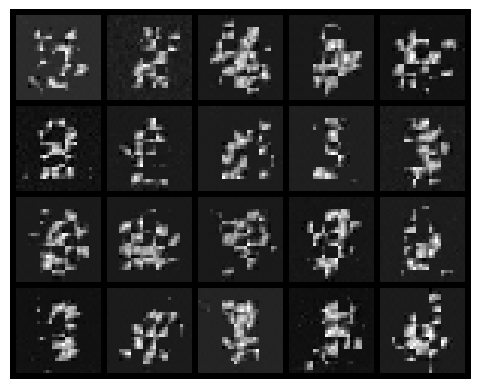

Avg Loss: 0.31254338576341234


Avg Loss: 0.2936266646233957


Avg Loss: 0.283924558618938


Avg Loss: 0.2776723609232445


Avg Loss: 0.27171212169470815


Avg Loss: 0.26429859450313326


Avg Loss: 0.25428219301614174


Avg Loss: 0.23700194912297384


Avg Loss: 0.22717693694301253


Avg Loss: 0.22237224166772004
Epoch: 11
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 117.51954650878906


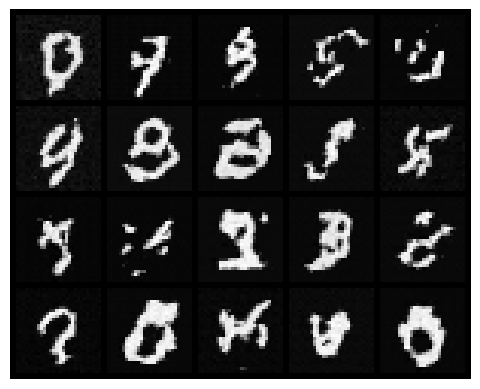

Avg Loss: 0.21821534060148287


Avg Loss: 0.21470590676071802


Avg Loss: 0.21206821757021235


Avg Loss: 0.20916343083196104


Avg Loss: 0.2084239074575113


Avg Loss: 0.20585414147707445


Avg Loss: 0.20492028017669345


Avg Loss: 0.20270774599267985


Avg Loss: 0.20133208766230135


Avg Loss: 0.2006284093647115
Epoch: 21
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 68.60763549804688


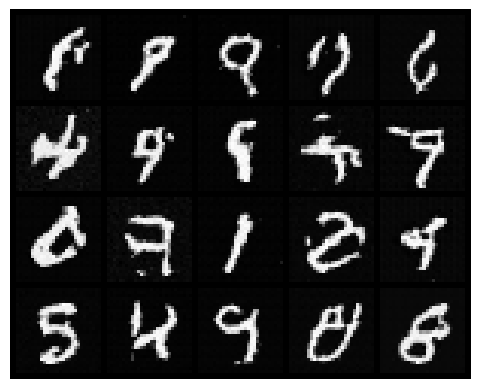

Avg Loss: 0.19944537709008403


Avg Loss: 0.19819679810230667


Avg Loss: 0.19776811364934896


Avg Loss: 0.19804610645593101


Avg Loss: 0.1962202341158761


Avg Loss: 0.19587647725841892


Avg Loss: 0.19533499481200156


Avg Loss: 0.19418713348760788


Avg Loss: 0.19345388683810164


Avg Loss: 0.19358739212377749
Epoch: 31
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 62.56571960449219


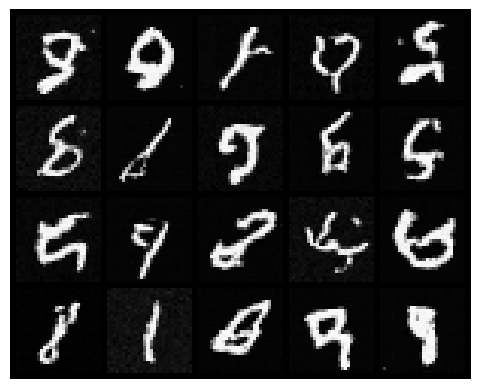

Avg Loss: 0.19240325964145313


Avg Loss: 0.19205581442887848


Avg Loss: 0.1913443936595022


Avg Loss: 0.1907268982452116


Avg Loss: 0.19081220586798084


Avg Loss: 0.19009040680521333


Avg Loss: 0.18926881336327048


Avg Loss: 0.1899891128576895


Avg Loss: 0.1893752607773108


Avg Loss: 0.18919819351960857
Epoch: 41
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 68.69264221191406


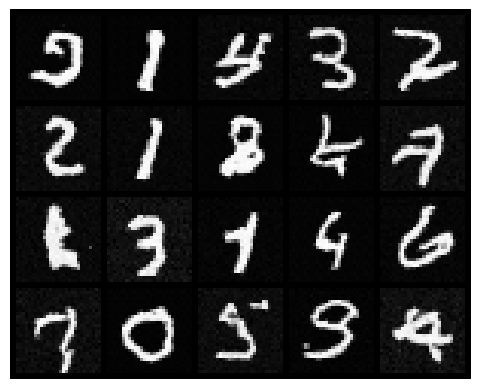

Avg Loss: 0.1884171547951983


Avg Loss: 0.1900391636658579


Avg Loss: 0.1880593075395139


Avg Loss: 0.18810625296475283


Avg Loss: 0.18682405185788425


Avg Loss: 0.18712255762202906


Avg Loss: 0.18651293950485015


Avg Loss: 0.1865867636859544


Avg Loss: 0.1867937495205194


Avg Loss: 0.18636793260381165
Epoch: 51
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 42.45537185668945


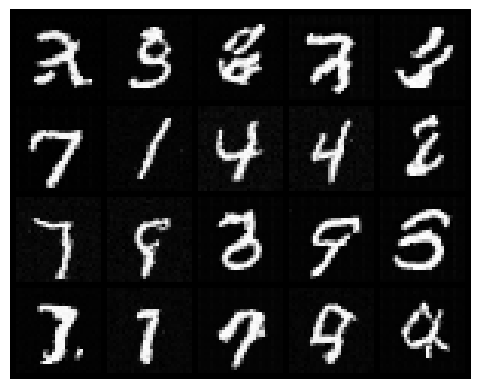

Avg Loss: 0.1859129163375033


Avg Loss: 0.18506062601103204


Avg Loss: 0.18641728269202368


Avg Loss: 0.1857982014002068


Avg Loss: 0.1846555320343483


Avg Loss: 0.18553841922646647


Avg Loss: 0.1841710840842363


Avg Loss: 0.18429387159057772


Avg Loss: 0.18635556014425464


Avg Loss: 0.18452309902860667
Epoch: 61
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 45.342811584472656


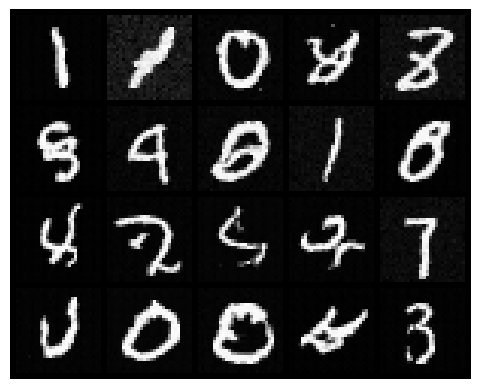

Avg Loss: 0.18353620751389563


Avg Loss: 0.1839753922337154


Avg Loss: 0.18312035702756727


Avg Loss: 0.18297145726965436


Avg Loss: 0.18335842404729014


Avg Loss: 0.1837557880227754


Avg Loss: 0.18337991930592035


Avg Loss: 0.18372279073574396


Avg Loss: 0.18187830260376942


Avg Loss: 0.18281418838099375
Epoch: 71
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 51.02205276489258


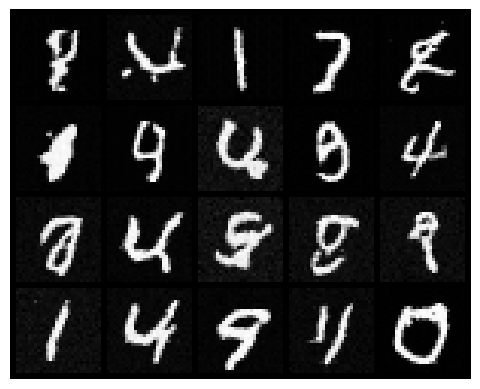

Avg Loss: 0.18474038555296754


Avg Loss: 0.18303342208043852


Avg Loss: 0.1822382842998769


Avg Loss: 0.18157438272987603


Avg Loss: 0.1817741882858246


Avg Loss: 0.18160381589108693


Avg Loss: 0.18131192489219372


Avg Loss: 0.18093215250003059


Avg Loss: 0.18237567146513253


Avg Loss: 0.18186562616370125
Epoch: 81
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 41.340789794921875


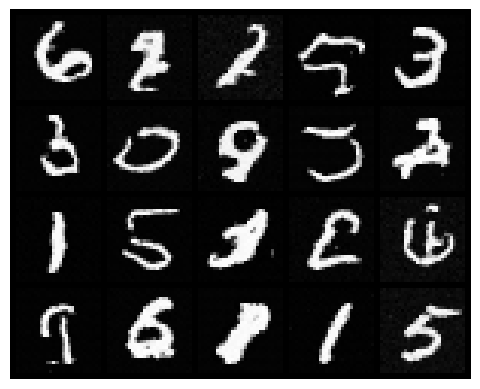

Avg Loss: 0.181448072179167


Avg Loss: 0.18047415611268616


Avg Loss: 0.18129946569453426


Avg Loss: 0.18019241085057575


Avg Loss: 0.18054988629210478


Avg Loss: 0.18056073516353108


Avg Loss: 0.18051896033002368


Avg Loss: 0.18091469888748135


Avg Loss: 0.18121616591586234


Avg Loss: 0.18040478343902622
Epoch: 91
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 43.822200775146484


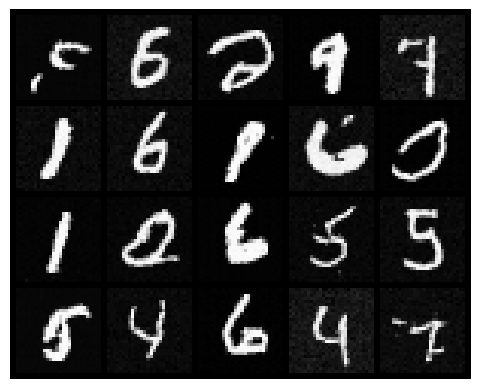

Avg Loss: 0.180329328502165


Avg Loss: 0.17999024476323808


Avg Loss: 0.18098889356419476


Avg Loss: 0.1797944222813222


Avg Loss: 0.17900165291165493


Avg Loss: 0.17919495411074238


Avg Loss: 0.1793282951341509


Avg Loss: 0.17971235246800665


Avg Loss: 0.1790445734824199
Final Epoch:


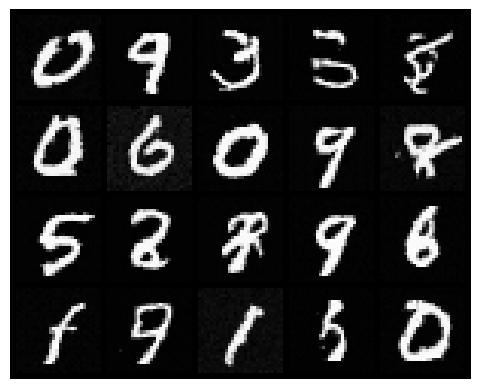

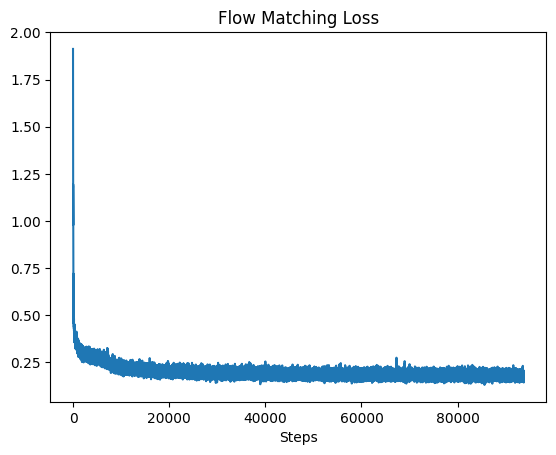

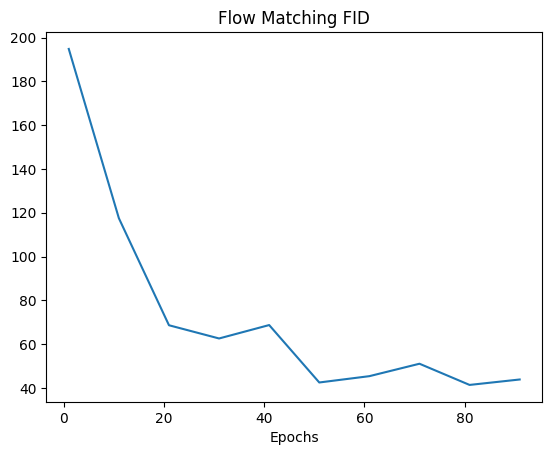

In [9]:
fm = FlowMatching()
fm.train()

## U-Net Diffusion

We implement DDPM using the traditional U-Net architecture instead of DiT.
The U-Net uses convolutional downsampling/upsampling blocks with skip connections,
and injects the timestep t via FCBlocks (fully-connected conditioning blocks).

In [15]:
# ── U-Net building blocks ──────────────────────────────────────────────────
import torch.nn as nn

class Conv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, 1, 1),
            nn.BatchNorm2d(out_ch),
            nn.GELU()
        )
    def forward(self, x):
        return self.net(x)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(Conv(in_ch, out_ch), Conv(out_ch, out_ch))
    def forward(self, x):
        return self.net(x)

class DownConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, 2, 1),
            nn.BatchNorm2d(out_ch),
            nn.GELU()
        )
    def forward(self, x):
        return self.net(x)

class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.down = DownConv(in_ch, out_ch)
        self.conv = ConvBlock(out_ch, out_ch)
    def forward(self, x):
        return self.conv(self.down(x))

class UpConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1),
            nn.BatchNorm2d(out_ch),
            nn.GELU()
        )
    def forward(self, x):
        return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = UpConv(in_ch, out_ch)
        self.conv = ConvBlock(out_ch, out_ch)
    def forward(self, x):
        return self.conv(self.up(x))

class FCBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_ch, out_ch),
            nn.GELU(),
            nn.Linear(out_ch, out_ch)
        )
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, D=64):
        super().__init__()
        self.D = D
        self.conv1  = Conv(channels, D)
        self.down1  = DownBlock(D, 2*D)
        self.down2  = DownBlock(2*D, 4*D)
        self.flatten   = nn.AvgPool2d(7)
        self.unflatten = nn.Sequential(
            nn.ConvTranspose2d(4*D, 4*D, 7),
            nn.BatchNorm2d(4*D),
            nn.GELU()
        )
        self.up1   = UpBlock(8*D, 2*D)
        self.up2   = UpBlock(4*D, D)
        self.conv2 = ConvBlock(2*D, D)
        self.out   = nn.Conv2d(D, channels, 1)
        self.fc1_t = FCBlock(1, 4*D)
        self.fc2_t = FCBlock(1, 2*D)

    def forward(self, x, t):
        t_norm = (t.float() / num_timesteps).view(-1, 1)
        t1 = self.fc1_t(t_norm).view(-1, 4*self.D, 1, 1)
        t2 = self.fc2_t(t_norm).view(-1, 2*self.D, 1, 1)

        x1 = self.conv1(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.flatten(x3)
        x4 = self.unflatten(x4) + t1
        x5 = self.up1(torch.cat([x4, x3], dim=1)) + t2
        x6 = self.up2(torch.cat([x5, x2], dim=1))
        x7 = self.conv2(torch.cat([x6, x1], dim=1))
        return self.out(x7)


class UNetDiffusion:

    def __init__(self):
        trans = transforms.Compose([
            transforms.Resize(res),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,)),
        ])
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.fid = FrechetInceptionDistance(feature=2048, normalize=True).to(self.device)
        self.num_fid_samples = 1000

        self.dataset = datasets.MNIST(root='./data', train=True, download=True, transform=trans)
        self.training_dataloader = DataLoader(self.dataset, batch_size=batch_size, shuffle=True)

        self.betas      = torch.linspace(beta_0, beta_t, num_timesteps).to(self.device)
        self.alphas     = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

        self.model     = UNet(D=64).to(self.device)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        self.loss_fn   = torch.nn.MSELoss()

        self._precompute_fid_real()

    def train(self):
        total_losses = []
        all_fids     = []
        fid_epochs   = []

        for e in range(num_epoch):
            self.model.train()
            all_losses = []

            for imgs, _ in tqdm(self.training_dataloader):
                imgs  = imgs.to(self.device)
                t     = torch.randint(0, num_timesteps, (imgs.shape[0],), device=self.device)
                noise = torch.randn_like(imgs)
                ab    = self.alphas_bar[t].view(-1, 1, 1, 1)
                x_t   = torch.sqrt(ab) * imgs + torch.sqrt(1.0 - ab) * noise

                noise_pred = self.model(x_t, t)
                loss = self.loss_fn(noise_pred, noise)

                self.optimizer.zero_grad()
                loss.backward()
                self.optimizer.step()
                all_losses.append(loss.item())

            print('Avg Loss:', sum(all_losses) / len(all_losses))
            total_losses += all_losses
            all_losses = []

            if e % 10 == 0:
                print('Epoch:', e + 1)
                torch.save(self.model.state_dict(), f'checkpoints/unet_epoch_{e}.pt')
                imgs    = self.run_inference()
                fid_val = self.compute_fid()
                print('FID:', fid_val)
                all_fids.append(fid_val)
                fid_epochs.append(e + 1)
                show_images(imgs)

        torch.save(self.model.state_dict(), 'checkpoints/unet_final.pt')
        print('Model saved in Drive.')

        print('Final Epoch:')
        show_images(self.run_inference())

        plt.plot(total_losses)
        plt.title('U-Net Diffusion Loss')
        plt.xlabel('Steps')
        plt.show()

        plt.plot(fid_epochs, all_fids)
        plt.title('U-Net Diffusion FID')
        plt.xlabel('Epochs')
        plt.show()

    def run_inference(self, num_samples=20):
        self.model.eval()
        with torch.no_grad():
            x = torch.randn(num_samples, channels, res, res, device=self.device)
            for t in reversed(range(num_timesteps)):
                t_tensor    = torch.full((num_samples,), t, device=self.device, dtype=torch.long)
                beta_t      = self.betas[t]
                alpha_t     = self.alphas[t]
                alpha_bar_t = self.alphas_bar[t]
                eps_pred    = self.model(x, t_tensor)
                coeff       = beta_t / torch.sqrt(1.0 - alpha_bar_t)
                mean        = (1.0 / torch.sqrt(alpha_t)) * (x - coeff * eps_pred)
                if t > 0:
                    x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
                else:
                    x = mean
            return x

    def _prepare_for_fid(self, imgs_m1_1):
        imgs = (imgs_m1_1 / 2 + 0.5).clamp(0, 1)
        imgs = imgs.repeat(1, 3, 1, 1)
        imgs = F.resize(imgs, [75, 75], antialias=True)
        return imgs

    def _precompute_fid_real(self):
        print(f'[FID] Pre-computing real features on up to {self.num_fid_samples} samples...')
        total = 0
        for imgs, _ in self.dataset:
            imgs = imgs.to(self.device)
            imgs = self._prepare_for_fid(imgs)
            self.fid.update(imgs, real=True)
            total += imgs.size(0)
            if total >= self.num_fid_samples:
                break
        print(f'[FID] Real features ready ({total} samples).')

    @torch.no_grad()
    def compute_fid(self):
        self.model.eval()
        batch  = 200
        needed = self.num_fid_samples
        done   = 0
        while done < needed:
            n    = min(batch, needed - done)
            fake = self.run_inference(num_samples=n)
            fake = self._prepare_for_fid(fake.to(self.device))
            self.fid.update(fake, real=False)
            done += n
        val = float(self.fid.compute().item())
        self.fid.reset()
        self._precompute_fid_real()
        self.model.train()
        return val

[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).


Avg Loss: 0.08306761447395851
Epoch: 1
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 78.201416015625


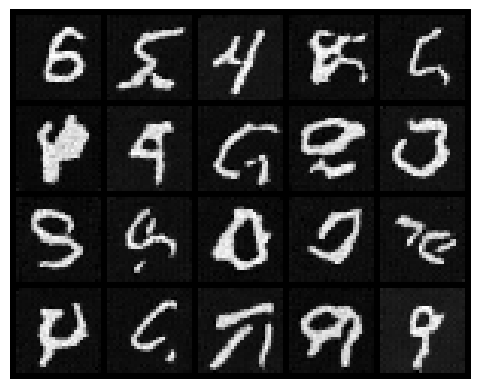

Avg Loss: 0.055933721800412194


Avg Loss: 0.05071743660326451


Avg Loss: 0.04827855233905285


Avg Loss: 0.04652304822273219


Avg Loss: 0.04520881408329076


Avg Loss: 0.04464656976200561


Avg Loss: 0.04372693785924965


Avg Loss: 0.04358443531837227


Avg Loss: 0.04308058408452377


Avg Loss: 0.04257626101366683
Epoch: 11
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 57.29460144042969


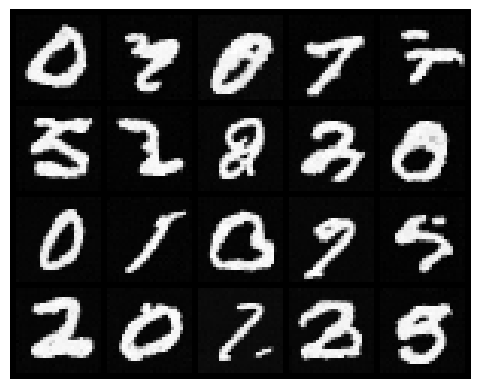

Avg Loss: 0.042214739652696065


Avg Loss: 0.041912844777901546


Avg Loss: 0.04159632669702204


Avg Loss: 0.041301010257955684


Avg Loss: 0.041220306891447574


Avg Loss: 0.041201278184062


Avg Loss: 0.04068051419778864


Avg Loss: 0.04078973284853039


Avg Loss: 0.040614200632836515


Avg Loss: 0.04032951042548553
Epoch: 21
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 38.585731506347656


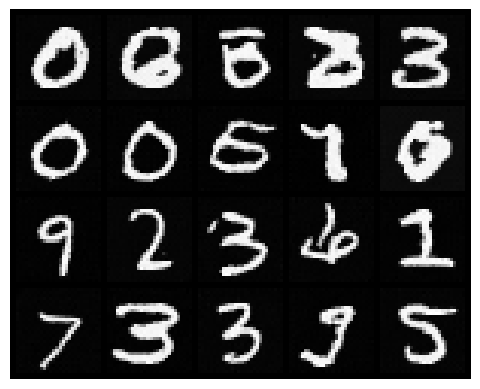

Avg Loss: 0.0402478542782541


Avg Loss: 0.04027210015938607


Avg Loss: 0.03995328132253784


Avg Loss: 0.03993064987419574


Avg Loss: 0.03966991085487642


Avg Loss: 0.039647188551946363


Avg Loss: 0.03943717293044143


Avg Loss: 0.0393331975185636


Avg Loss: 0.03912166803717804


Avg Loss: 0.03904362898796543
Epoch: 31
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 25.68003273010254


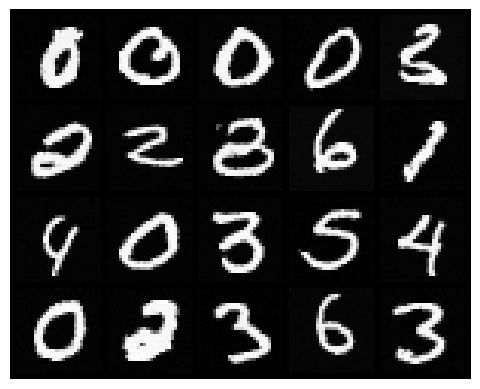

Avg Loss: 0.0391362242277529


Avg Loss: 0.0389634680602628


Avg Loss: 0.03865600879719135


Avg Loss: 0.038896424388056246


Avg Loss: 0.03871673565588272


Avg Loss: 0.03867614760137062


Avg Loss: 0.03847860125129792


Avg Loss: 0.03869799272552418


Avg Loss: 0.03849801188632687


Avg Loss: 0.03858866692105654
Epoch: 41
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 24.448036193847656


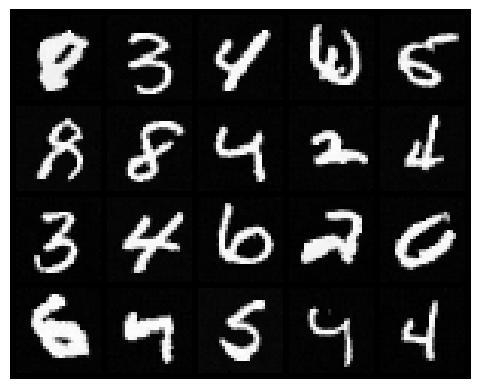

Avg Loss: 0.038292247130831424


Avg Loss: 0.03853705339332316


Avg Loss: 0.03838196021121448


Avg Loss: 0.038241189560974075


Avg Loss: 0.03824567801551397


Avg Loss: 0.03840734278247046


Avg Loss: 0.03800668155571926


Avg Loss: 0.037864170650810575


Avg Loss: 0.03811030897861922


Avg Loss: 0.03786897623955187
Epoch: 51
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 23.357166290283203


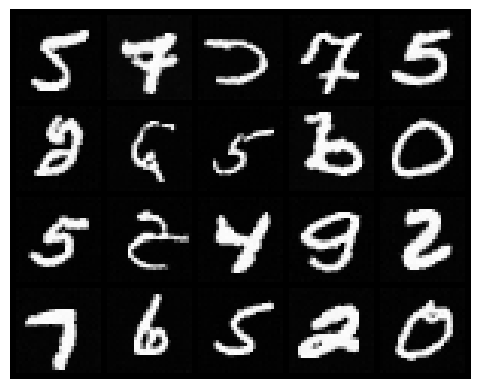

Avg Loss: 0.03807014537089542


Avg Loss: 0.03769411068203162


Avg Loss: 0.03780568456614831


Avg Loss: 0.03775299955079995


Avg Loss: 0.037889826991188244


Avg Loss: 0.037856817122366125


Avg Loss: 0.03785154798518874


Avg Loss: 0.03787092220927797


Avg Loss: 0.03782640590366206


Avg Loss: 0.03766849607046543
Epoch: 61
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 27.367971420288086


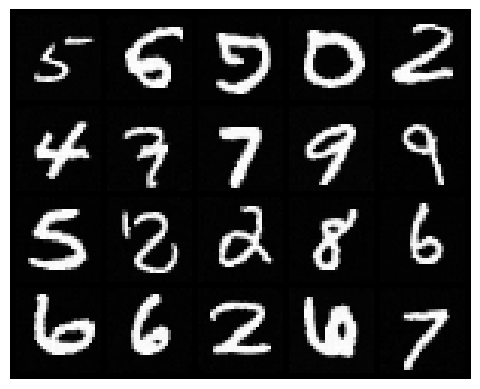

Avg Loss: 0.037792769717429876


Avg Loss: 0.03756174410997169


Avg Loss: 0.03741457158211134


Avg Loss: 0.03771965530341559


Avg Loss: 0.03755052851588487


Avg Loss: 0.03735731041301161


Avg Loss: 0.0376260856976673


Avg Loss: 0.037597225748622086


Avg Loss: 0.03752159343551852


Avg Loss: 0.03729411749157316
Epoch: 71
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 21.86299705505371


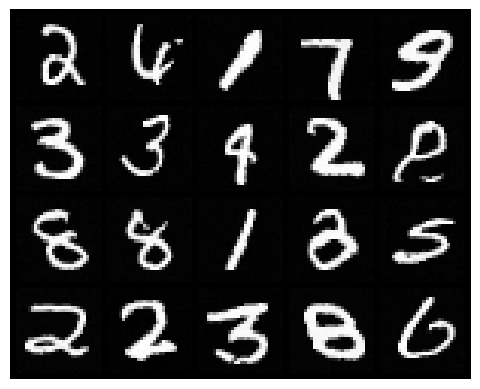

Avg Loss: 0.03752575519639673


Avg Loss: 0.03729971565171155


Avg Loss: 0.037257135200347985


Avg Loss: 0.03726865936404289


Avg Loss: 0.03747670818120241


Avg Loss: 0.037106810282590164


Avg Loss: 0.03735839713142434


Avg Loss: 0.037001853346078


Avg Loss: 0.03695748482884438


Avg Loss: 0.037121342300479095
Epoch: 81
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 21.45711898803711


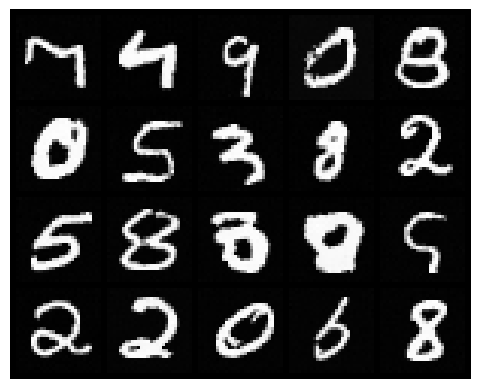

Avg Loss: 0.03727940171321572


Avg Loss: 0.037006027114861555


Avg Loss: 0.03710599094510142


Avg Loss: 0.03687784484208329


Avg Loss: 0.03710399935645526


Avg Loss: 0.03705886698393489


Avg Loss: 0.03688763793923262


Avg Loss: 0.03680262246778779


Avg Loss: 0.036811505573422415


Avg Loss: 0.03686594858424051
Epoch: 91
[FID] Pre-computing real features on up to 1000 samples...
[FID] Real features ready (1000 samples).
FID: 23.130613327026367


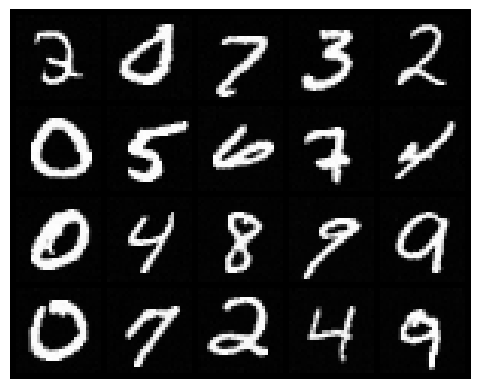

Avg Loss: 0.03668549438434115


Avg Loss: 0.036713339273196297


Avg Loss: 0.036912958435555386


Avg Loss: 0.03695311415781662


Avg Loss: 0.03688724752245491


Avg Loss: 0.03681609214448344


Avg Loss: 0.03655329190973026


Avg Loss: 0.036714197670631825


Avg Loss: 0.0367079645411165
Modelo guardado en Drive.
Final Epoch:


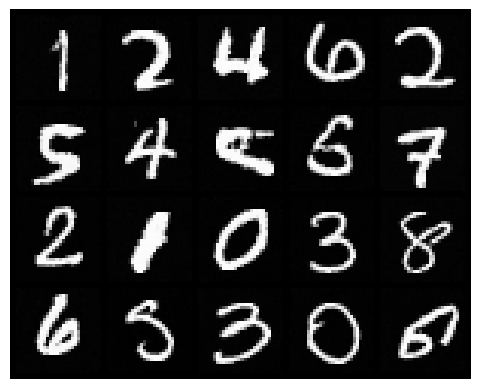

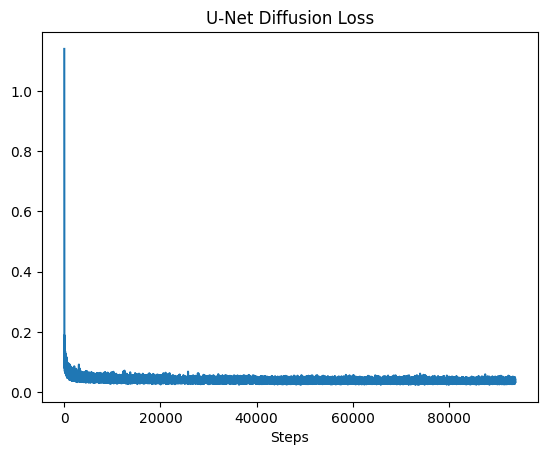

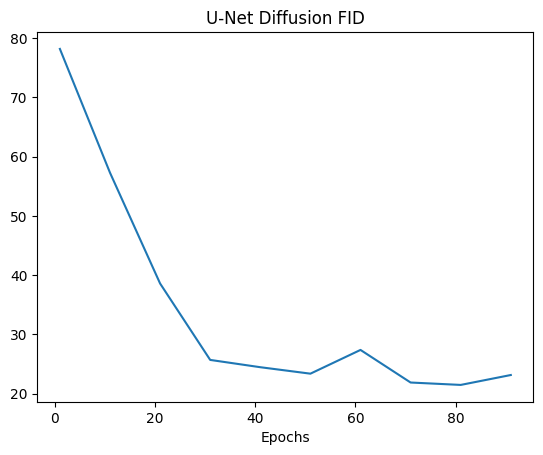

In [16]:
unet = UNetDiffusion()
unet.train()

## Latent Diffusion with SDXL VAE.


In [14]:
from diffusers import AutoencoderKL
vae = AutoencoderKL.from_pretrained("stabilityai/sdxl-vae").to("cuda")
print("VAE loaded successfully")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


VAE cargado correctamente


CelebA is loaded from the Kaggle mirror (`img_align_celeba.zip`, see the README for the download link) and unzipped into `data/celeba/`.


In [23]:
!unzip -q "data/img_align_celeba.zip" -d data/celeba/
print(f"Done: {len(os.listdir('data/celeba/'))} images")

Listo: 2 imágenes


In [26]:
from diffusers import AutoencoderKL
from torch.utils.data import Dataset
from PIL import Image

# Latent Diffusion hyperparameters
ld_res        = 64
ld_patch_size = 4
ld_latent_ch  = 4
ld_latent_res = 8
ld_num_patch  = (ld_latent_res // ld_patch_size) ** 2
ld_hidden_dim = 256
ld_ff_dim     = 1024
ld_time_emb   = 256
ld_num_blocks = 5
ld_heads      = 8
ld_num_ts     = 300
ld_batch      = 32
ld_lr         = 4e-4
ld_epochs     = 100
ld_beta0      = 0.0001
ld_betaT      = 0.02

class CelebADataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir   = img_dir
        self.transform = transform
        self.imgs      = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.img_dir, self.imgs[idx])).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, 0


class LatentDiffusion:

    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # Load pretrained SDXL VAE and freeze it
        self.vae = AutoencoderKL.from_pretrained("stabilityai/sdxl-vae").to(self.device)
        self.vae.eval()
        for p in self.vae.parameters():
            p.requires_grad = False
        print("VAE loaded and frozen")

        # CelebA dataset from Colab local storage
        trans = transforms.Compose([
            transforms.Resize(ld_res),
            transforms.CenterCrop(ld_res),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ])
        self.dataset    = CelebADataset('data/celeba/img_align_celeba/', transform=trans)
        self.dataloader = DataLoader(self.dataset, batch_size=ld_batch,
                                     shuffle=True, num_workers=2)
        print(f"CelebA dataset loaded: {len(self.dataset)} images")

        # DDPM noise schedule
        self.betas      = torch.linspace(ld_beta0, ld_betaT, ld_num_ts).to(self.device)
        self.alphas     = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

        # DiT operating on latents instead of pixels
        self.model = DiT(
            patch_size=ld_patch_size,
            num_blocks=ld_num_blocks,
            num_heads=ld_heads,
            ff_dim=ld_ff_dim,
            time_emb_dim=ld_time_emb,
            num_timesteps=ld_num_ts,
            hidden_dim=ld_hidden_dim,
            num_patches=ld_num_patch,
            num_channels=ld_latent_ch,
        ).to(self.device)

        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=ld_lr)
        self.loss_fn   = torch.nn.MSELoss()

        self.fid = FrechetInceptionDistance(feature=2048, normalize=True).to(self.device)
        self.num_fid_samples = 1000
        self._precompute_fid_real()

    @torch.no_grad()
    def encode(self, imgs):
        # Encode images to latent space using the VAE
        latents = self.vae.encode(imgs).latent_dist.mean
        # Scale latents (SDXL convention)
        latents = latents * 0.13025
        return latents

    @torch.no_grad()
    def decode(self, latents):
        # Unscale and decode latents back to images
        latents = latents / 0.13025
        imgs = self.vae.decode(latents).sample
        return imgs

    def train(self):
        total_losses = []
        all_fids     = []
        fid_epochs   = []

        for e in range(ld_epochs):
            self.model.train()
            all_losses = []

            for imgs, _ in tqdm(self.dataloader):
                imgs = imgs.to(self.device)

                # Encode images to latent space
                latents = self.encode(imgs)

                # Sample random timestep and noise
                t     = torch.randint(0, ld_num_ts, (latents.shape[0],), device=self.device)
                noise = torch.randn_like(latents)

                # Forward diffusion process
                ab  = self.alphas_bar[t].view(-1, 1, 1, 1)
                x_t = torch.sqrt(ab) * latents + torch.sqrt(1.0 - ab) * noise

                # Predict noise and compute loss
                noise_pred = self.model(x_t, t)
                loss = self.loss_fn(noise_pred, noise)

                self.optimizer.zero_grad()
                loss.backward()
                self.optimizer.step()
                all_losses.append(loss.item())

            print(f'Epoch {e+1} - Avg Loss: {sum(all_losses)/len(all_losses):.4f}')
            total_losses += all_losses

            if e % 10 == 0:
                # Save checkpoint to Drive
                torch.save(self.model.state_dict(),
                           f'checkpoints/ldm_epoch_{e}.pt')
                imgs_gen = self.run_inference()
                fid_val  = self.compute_fid()
                print(f'FID: {fid_val:.2f}')
                all_fids.append(fid_val)
                fid_epochs.append(e + 1)
                show_images(imgs_gen)

        # Save final model
        torch.save(self.model.state_dict(), 'checkpoints/ldm_final.pt')
        print('Model saved to Drive.')

        print('Final Epoch:')
        show_images(self.run_inference())

        plt.plot(total_losses)
        plt.title('Latent Diffusion Loss')
        plt.xlabel('Steps')
        plt.show()

        plt.plot(fid_epochs, all_fids)
        plt.title('Latent Diffusion FID')
        plt.xlabel('Epochs')
        plt.show()

    @torch.no_grad()
    def run_inference(self, num_samples=20):
        self.model.eval()

        # Start from pure noise in latent space
        x = torch.randn(num_samples, ld_latent_ch, ld_latent_res, ld_latent_res,
                        device=self.device)

        # Iterative denoising (DDPM reverse process)
        for t in reversed(range(ld_num_ts)):
            t_tensor    = torch.full((num_samples,), t, device=self.device, dtype=torch.long)
            beta_t      = self.betas[t]
            alpha_t     = self.alphas[t]
            alpha_bar_t = self.alphas_bar[t]
            eps_pred    = self.model(x, t_tensor)
            coeff       = beta_t / torch.sqrt(1.0 - alpha_bar_t)
            mean        = (1.0 / torch.sqrt(alpha_t)) * (x - coeff * eps_pred)
            if t > 0:
                x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
            else:
                x = mean

        # Decode latents to images using the VAE
        imgs = self.decode(x).clamp(-1, 1)
        return imgs

    def _prepare_for_fid(self, imgs):
        imgs = (imgs / 2 + 0.5).clamp(0, 1)
        imgs = F.resize(imgs, [75, 75], antialias=True)
        return imgs

    def _precompute_fid_real(self):
        print('[FID] Pre-computing real features...')
        total = 0
        for imgs, _ in self.dataloader:
            imgs = imgs.to(self.device)
            imgs = self._prepare_for_fid(imgs)
            self.fid.update(imgs, real=True)
            total += imgs.size(0)
            if total >= self.num_fid_samples:
                break
        print(f'[FID] Real features ready ({total} samples).')

    @torch.no_grad()
    def compute_fid(self):
        self.model.eval()
        batch  = 50
        needed = self.num_fid_samples
        done   = 0
        while done < needed:
            n    = min(batch, needed - done)
            fake = self.run_inference(num_samples=n)
            fake = self._prepare_for_fid(fake.to(self.device))
            self.fid.update(fake, real=False)
            done += n
        val = float(self.fid.compute().item())
        self.fid.reset()
        self._precompute_fid_real()
        self.model.train()
        return val

VAE loaded and frozen
CelebA dataset loaded: 202599 images
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).


Epoch 1 - Avg Loss: 0.3910
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 278.73


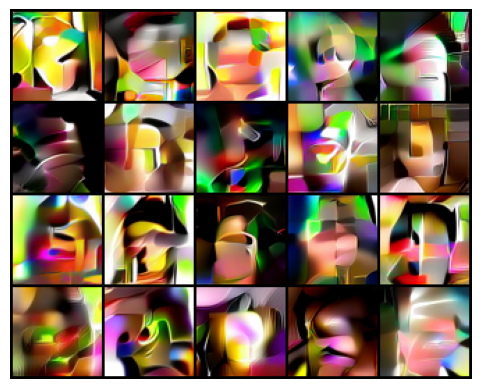

Epoch 2 - Avg Loss: 0.3598


Epoch 3 - Avg Loss: 0.3488


Epoch 4 - Avg Loss: 0.3429


Epoch 5 - Avg Loss: 0.3350


Epoch 6 - Avg Loss: 0.3300


Epoch 7 - Avg Loss: 0.3267


Epoch 8 - Avg Loss: 0.3253


Epoch 9 - Avg Loss: 0.3219


Epoch 10 - Avg Loss: 0.3204


Epoch 11 - Avg Loss: 0.3176
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 181.63


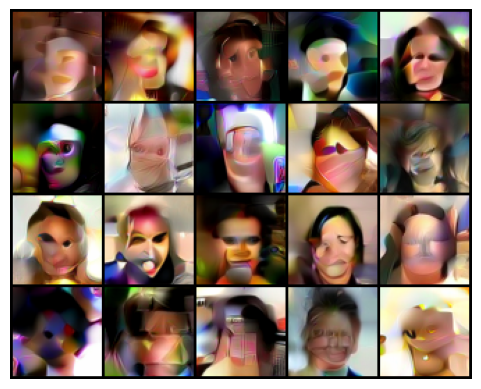

Epoch 12 - Avg Loss: 0.3170


Epoch 13 - Avg Loss: 0.3158


Epoch 14 - Avg Loss: 0.3150


Epoch 15 - Avg Loss: 0.3142


Epoch 16 - Avg Loss: 0.3133


Epoch 17 - Avg Loss: 0.3138


Epoch 18 - Avg Loss: 0.3131


Epoch 19 - Avg Loss: 0.3110


Epoch 20 - Avg Loss: 0.3115


Epoch 21 - Avg Loss: 0.3100
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 136.87


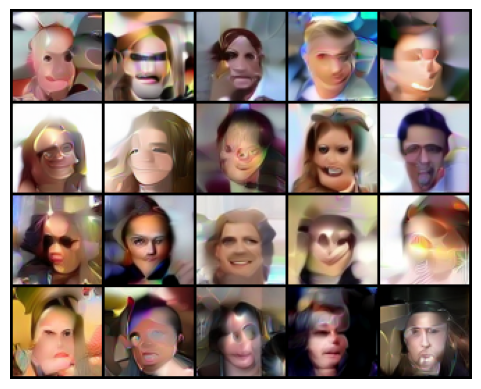

Epoch 22 - Avg Loss: 0.3106


Epoch 23 - Avg Loss: 0.3095


Epoch 24 - Avg Loss: 0.3081


Epoch 25 - Avg Loss: 0.3090


Epoch 26 - Avg Loss: 0.3086


Epoch 27 - Avg Loss: 0.3081


Epoch 28 - Avg Loss: 0.3084


Epoch 29 - Avg Loss: 0.3083


Epoch 30 - Avg Loss: 0.3071


Epoch 31 - Avg Loss: 0.3064
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 139.44


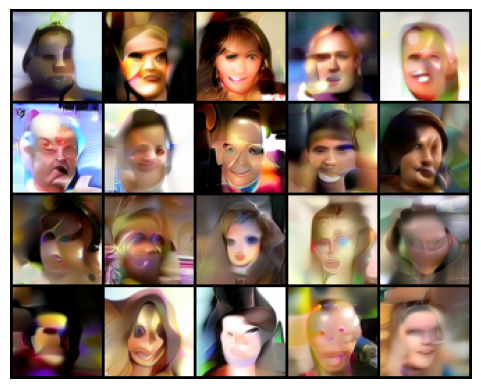

Epoch 32 - Avg Loss: 0.3067


Epoch 33 - Avg Loss: 0.3069


Epoch 34 - Avg Loss: 0.3065


Epoch 35 - Avg Loss: 0.3053


Epoch 36 - Avg Loss: 0.3055


Epoch 37 - Avg Loss: 0.3053


Epoch 38 - Avg Loss: 0.3061


Epoch 39 - Avg Loss: 0.3052


Epoch 40 - Avg Loss: 0.3042


Epoch 41 - Avg Loss: 0.3044
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 122.63


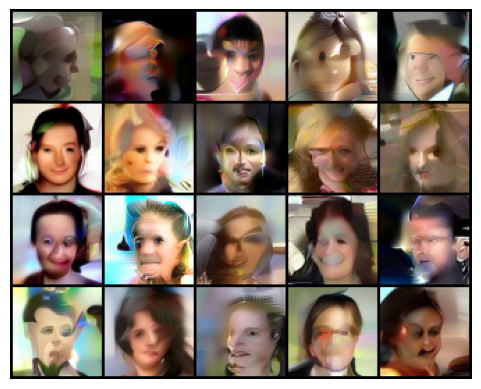

Epoch 42 - Avg Loss: 0.3041


Epoch 43 - Avg Loss: 0.3044


Epoch 44 - Avg Loss: 0.3033


Epoch 45 - Avg Loss: 0.3038


Epoch 46 - Avg Loss: 0.3046


Epoch 47 - Avg Loss: 0.3021


Epoch 48 - Avg Loss: 0.3031


Epoch 49 - Avg Loss: 0.3022


Epoch 50 - Avg Loss: 0.3028


Epoch 51 - Avg Loss: 0.3033
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 117.55


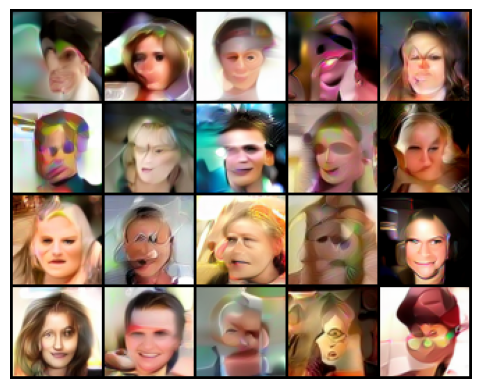

Epoch 52 - Avg Loss: 0.3025


Epoch 53 - Avg Loss: 0.3033


Epoch 54 - Avg Loss: 0.3030


Epoch 55 - Avg Loss: 0.3023


Epoch 56 - Avg Loss: 0.3023


Epoch 57 - Avg Loss: 0.3025


Epoch 58 - Avg Loss: 0.3020


Epoch 59 - Avg Loss: 0.3029


Epoch 60 - Avg Loss: 0.3016


Epoch 61 - Avg Loss: 0.3013
[FID] Pre-computing real features...
[FID] Real features ready (1024 samples).
FID: 132.36


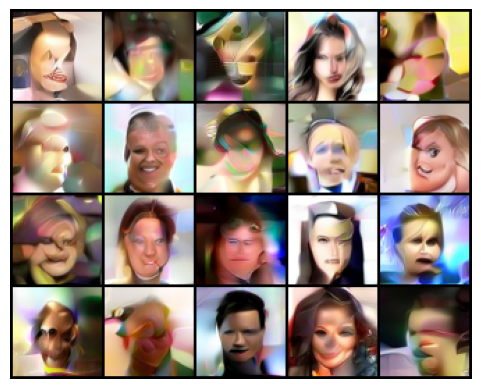

Epoch 62 - Avg Loss: 0.3032


Epoch 63 - Avg Loss: 0.3018


Epoch 64 - Avg Loss: 0.3012


Epoch 65 - Avg Loss: 0.3016


Epoch 66 - Avg Loss: 0.3020


Epoch 67 - Avg Loss: 0.3016


Epoch 68 - Avg Loss: 0.3017


In [ ]:
ldm = LatentDiffusion()
ldm.train()